# Motorcycle detector evaluation

Load a YOLO model checkpoint, confirm the model class map, and inspect boxes on representative original-resolution CCTV frames. The application adapter expects the motorcycle class index configured with classes attribute value (default 3 for COCO dataset) in predict method.

## Load detector

In [1]:
from ultralytics import YOLO

MODEL_PATH = 'yolo12n.pt'
model = YOLO(MODEL_PATH)

print(model.names)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

## Run one-frame inference

(np.float64(-0.5), np.float64(2567.5), np.float64(1439.5), np.float64(-0.5))

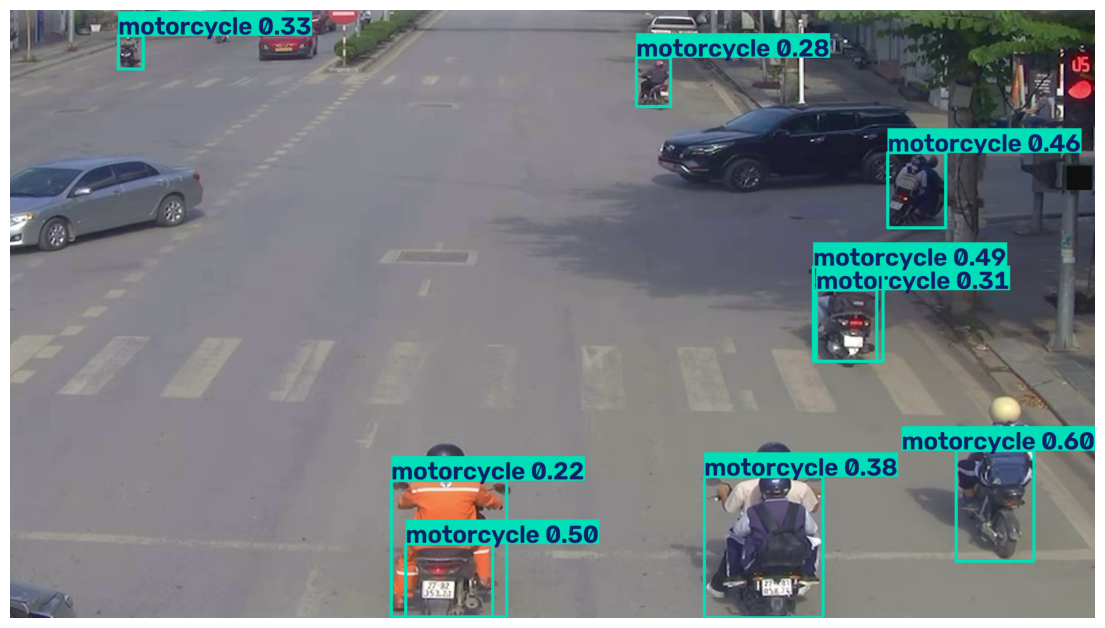

In [5]:
import cv2
import matplotlib.pyplot as plt

video_path = '../data/raw/video.mp4'
cap = cv2.VideoCapture(video_path)
target_classes = [3]

cap.set(cv2.CAP_PROP_POS_MSEC, 15 * 1000)
ok, frame = cap.read()
cap.release()

result = model.predict(frame, conf=0.20, classes=target_classes, verbose=False)[0]
annotated = result.plot()

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis('off')

## Record evaluation metadata

In [6]:
# Record checkpoint hash, class map, input size, confidence and labelled-set metrics before promoting the model.
import hashlib
from pathlib import Path

p = Path(MODEL_PATH)
sha256 = hashlib.sha256(p.read_bytes()).hexdigest()

print({'weights': str(p), 'sha256': sha256, 'class_map': model.names})

{'weights': 'yolo12n.pt', 'sha256': '419ff3dca37d69bacc93a50fa0c186a1c6f9fe62fae0f108b0872829689e9ca6', 'class_map': {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining t